# TCC — SRAG-COVID: Vacinação e Gravidade

Entradas esperadas:
- `base_covid_TODOS.csv`, gerado por `extrair_base_srag_covid.py`
- `resumos/resumo_mensal_TODOS.csv`, gerado por `resumir_srag.py`

**Escopo:** casos de SRAG-COVID (`CLASSI_FIN=5`) a partir de 2021, com desfecho
cura ou óbito por SRAG. O óbito por outras causas é excluído do alvo.

**Organização:**
- Seções 5-6: tabelas descritivas
- Seções 7-11: modelos de associação, do bruto ao ajustado por trimestre,
  e regressão de Poisson robusta
- Seções 12-14: XGBoost e SHAP
- Seções 15-18: sensibilidade, UTI, validação e OR por ano




## 1. Setup


In [6]:
import gc
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)


## 2. Carregar e filtrar a base

Lê só as colunas necessárias (o arquivo tem ~2,3 milhões de linhas).

In [7]:
CAMINHO_CSV = "base_covid_TODOS.csv"

COLS = [
    "DT_NOTIFIC", "IDADE_ANOS", "CS_SEXO", "CS_RACA", "SG_UF",
    "CARDIOPATI", "HEMATOLOGI", "SIND_DOWN", "HEPATICA", "ASMA", "DIABETES",
    "NEUROLOGIC", "PNEUMOPATI", "IMUNODEPRE", "RENAL", "OBESIDADE",
    "VACINA_COV", "EVOLUCAO", "UTI",
]

df = pd.read_csv(CAMINHO_CSV, usecols=COLS)
df["DT_NOTIFIC"] = pd.to_datetime(df["DT_NOTIFIC"], errors="coerce")
df["ano"] = df["DT_NOTIFIC"].dt.year


df = df[df["ano"] >= 2021].copy()
print(f"Casos SRAG-COVID 2021-2026: {len(df):,}")


Casos SRAG-COVID 2021-2026: 1,614,362


## 3. Engenharia de atributos

- Comorbidades: contamos quantas vieram marcadas como "Sim" (1). Valor
  ausente não é tratado como "não tem a comorbidade": é sinalizado à parte
  (`COMORBIDADE_TODAS_FALTANTES`).
- Vacinação: categorizamos explicitamente, sem assumir "não informado" como
  "não vacinado".


In [8]:
COMORBIDADES = [
    "CARDIOPATI", "HEMATOLOGI", "SIND_DOWN", "HEPATICA", "ASMA", "DIABETES",
    "NEUROLOGIC", "PNEUMOPATI", "IMUNODEPRE", "RENAL", "OBESIDADE",
]

df["N_COMORBIDADES"] = (df[COMORBIDADES] == 1).sum(axis=1)
df["COMORBIDADE_TODAS_FALTANTES"] = df[COMORBIDADES].isna().all(axis=1).astype(int)

df["VACINA_CAT"] = df["VACINA_COV"].map({1.0: "Sim", 2.0: "Nao", 9.0: "Ignorado"}).fillna("Nao_informado")

print(df["VACINA_CAT"].value_counts())
print()
print(df["N_COMORBIDADES"].describe())


VACINA_CAT
Sim              528634
Nao              517528
Nao_informado    344757
Ignorado         223443
Name: count, dtype: int64

count    1.614362e+06
mean     7.569932e-01
std      9.334473e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      1.000000e+00
max      1.100000e+01
Name: N_COMORBIDADES, dtype: float64


## 4. Base de modelagem

Restringe a:
- Status vacinal `Sim` ou `Nao` (`Ignorado` e `Nao_informado` entram só na
  análise de sensibilidade, seção 15).
- Desfecho cura (`EVOLUCAO=1`) ou óbito por SRAG (`EVOLUCAO=2`).
- Sexo registrado como M/F e idade conhecida.

Também cria o trimestre de notificação, usado no ajuste por período.

In [9]:
base = df[
    df["VACINA_CAT"].isin(["Sim", "Nao"])
    & df["EVOLUCAO"].isin([1, 2])
    & df["CS_SEXO"].isin(["M", "F"])
    & df["IDADE_ANOS"].notna()
].copy()

base["OBITO"] = (base["EVOLUCAO"] == 2).astype(int)
base["VACINADO"] = (base["VACINA_CAT"] == "Sim").astype(int)
base["SEXO_M"] = (base["CS_SEXO"] == "M").astype(int)
base["TRIMESTRE"] = base["DT_NOTIFIC"].dt.to_period("Q").astype(str)

print(f"Casos na base de modelagem: {len(base):,}")
print(f"Vacinados: {base['VACINADO'].sum():,} | Nao vacinados: {(1 - base['VACINADO']).sum():,}")
print(f"Taxa de obito: {base['OBITO'].mean()*100:.1f}%")
print(f"Casos com idade acima de 110 anos: {(base['IDADE_ANOS'] > 110).sum()}")


Casos na base de modelagem: 983,492
Vacinados: 494,860 | Nao vacinados: 488,632
Taxa de obito: 30.5%
Casos com idade acima de 110 anos: 28


## 5. Tabela 1: série anual de SRAG, SRAG-COVID e letalidade

- Casos de SRAG e de COVID: do resumo mensal.
- Letalidade da SRAG-COVID: óbitos por SRAG (`EVOLUCAO=2`) sobre os casos com
  desfecho conhecido (`EVOLUCAO` 1, 2 ou 3), como definido na metodologia.



In [10]:
CAMINHO_RESUMO = "resumo_mensal_TODOS.csv"

mensal = pd.read_csv(CAMINHO_RESUMO)
print("Arquivos usados na serie:", sorted(mensal["arquivo_origem"].unique()))

# Um mesmo mes pode vir de dois arquivos (notificacoes tardias): soma por mes
por_mes = mensal.groupby("mes")[["total_casos", "casos_covid"]].sum()
por_mes["pct_covid"] = por_mes["casos_covid"] / por_mes["total_casos"] * 100

mensal["ano"] = mensal["mes"].str[:4].astype(int)
tabela1 = mensal[mensal["ano"] >= 2019].groupby("ano")[["total_casos", "casos_covid"]].sum()
tabela1["pct_covid"] = (tabela1["casos_covid"] / tabela1["total_casos"] * 100).round(1)

# Letalidade da SRAG-COVID por ano, a partir da base individual (2020-2026)
let = pd.read_csv(CAMINHO_CSV, usecols=["DT_NOTIFIC", "EVOLUCAO"])
let["ano"] = pd.to_datetime(let["DT_NOTIFIC"], errors="coerce").dt.year
let = let[let["EVOLUCAO"].isin([1, 2, 3]) & let["ano"].notna()]
let["ano"] = let["ano"].astype(int)
tabela1["letalidade_covid_pct"] = ((let["EVOLUCAO"] == 2).groupby(let["ano"]).mean() * 100).round(1)
del let
gc.collect()

print()
print("Tabela 1:")
print(tabela1)

pico = por_mes["total_casos"].idxmax()
print()
print(f"Mes de pico: {pico} | {por_mes.loc[pico, 'total_casos']:,.0f} casos, "
      f"{por_mes.loc[pico, 'casos_covid']:,.0f} de COVID ({por_mes.loc[pico, 'pct_covid']:.1f}%)")
print("Primeiro mes com COVID:", por_mes[por_mes["casos_covid"] > 0].index.min())
for a in ["2024", "2025", "2026"]:
    sub = por_mes[por_mes.index.str.startswith(a)]
    print(f"{a}: % COVID mensal entre {sub['pct_covid'].min():.1f} e {sub['pct_covid'].max():.1f}")


Arquivos usados na serie: ['INFLUD19-23-03-2026', 'INFLUD20-23-03-2026', 'INFLUD21-23-03-2026', 'INFLUD22-23-03-2026', 'INFLUD23-23-03-2026', 'INFLUD24-23-03-2026', 'INFLUD25-14-09-2026', 'INFLUD26-14-09-2026']

Tabela 1:
      total_casos  casos_covid  pct_covid  letalidade_covid_pct
ano                                                            
2019        48634            0        0.0                   NaN
2020      1148787       677260       59.0                  33.6
2021      1773875      1258682       71.0                  33.4
2022       582656       247486       42.5                  28.6
2023       284383        53357       18.8                  21.1
2024       268519        31518       11.7                  18.6
2025       334580        18151        5.4                  16.0
2026       216781         5013        2.3                  15.7

Mes de pico: 2021-03 | 301,692 casos, 248,149 de COVID (82.3%)
Primeiro mes com COVID: 2020-02
2024: % COVID mensal entre 2.6 e 36.3
2025

## 6. Tabelas 2 e 3: perfil de vacinados e não vacinados

Base de modelagem. A Tabela 3 mostra a proporção de óbitos (entre cura e
óbito) por faixa etária e status vacinal.

In [11]:
g = base.groupby("VACINADO")
pct = lambda serie: (serie.groupby(base["VACINADO"]).mean() * 100).round(1)

base["FAIXA_ETARIA"] = pd.cut(
    base["IDADE_ANOS"], bins=[0, 18, 40, 60, 75, 200],
    labels=["0-17", "18-39", "40-59", "60-74", "75+"], right=False,
)

tabela2 = pd.DataFrame({
    "n": g.size(),
    "Idade média (anos)": g["IDADE_ANOS"].mean().round(1),
    "Idade mediana (anos)": g["IDADE_ANOS"].median(),
    "75 anos ou mais (%)": pct(base["FAIXA_ETARIA"] == "75+"),
    "Sexo masculino (%)": pct(base["SEXO_M"]),
    "Pelo menos uma comorbidade (%)": pct(base["N_COMORBIDADES"] > 0),
    "Comorbidades todas vazias (%)": pct(base["COMORBIDADE_TODAS_FALTANTES"]),
    "Doença cardiovascular (%)": pct(base["CARDIOPATI"] == 1),
    "Diabetes (%)": pct(base["DIABETES"] == 1),
    "Obesidade (%)": pct(base["OBESIDADE"] == 1),
    "Óbito (%)": pct(base["OBITO"]),
}).T
tabela2.columns = ["Não vacinados", "Vacinados"]
print("Tabela 2:")
print(tabela2)

tabela3 = (base.groupby(["FAIXA_ETARIA", "VACINADO"], observed=True)["OBITO"].mean().unstack() * 100).round(1)
tabela3.columns = ["Não vacinados", "Vacinados"]
print()
print("Tabela 3 (% de obitos):")
print(tabela3)

prevalencias = (base.groupby("VACINADO")[COMORBIDADES].apply(lambda x: (x == 1).mean() * 100)).T.round(1)
prevalencias.columns = ["Não vacinados", "Vacinados"]
print()
print("Prevalencia de cada comorbidade (%):")
print(prevalencias.sort_values("Vacinados", ascending=False))


Tabela 2:
                                Não vacinados  Vacinados
n                                    488632.0   494860.0
Idade média (anos)                       49.7       65.1
Idade mediana (anos)                     51.0       68.0
75 anos ou mais (%)                      11.1       36.5
Sexo masculino (%)                       56.7       51.0
Pelo menos uma comorbidade (%)           41.8       59.3
Comorbidades todas vazias (%)            52.0       34.3
Doença cardiovascular (%)                23.8       38.0
Diabetes (%)                             16.1       25.7
Obesidade (%)                             9.3        7.3
Óbito (%)                                31.2       29.8

Tabela 3 (% de obitos):
              Não vacinados  Vacinados
FAIXA_ETARIA                          
0-17                    4.3        3.4
18-39                  16.5        8.2
40-59                  28.8       17.2
60-74                  47.0       32.5
75+                    55.8       42.1

Prevale

## 7. Modelo bruto (sem ajuste)

Só a vacinação prevendo o óbito, sem controlar idade nem comorbidades.

In [12]:
def extrair(modelo, nome, medida, var="VACINADO"):
    est = np.exp(modelo.params[var])
    lo, hi = np.exp(modelo.conf_int().loc[var])
    return {"Modelo": nome, "Medida": medida, "Estimativa": round(float(est), 3),
            "IC 95% inf": round(float(lo), 3), "IC 95% sup": round(float(hi), 3)}

resultados_modelos = []  # vira a Tabela 4

modelo_bruto = smf.logit("OBITO ~ VACINADO", data=base).fit()
resultados_modelos.append(extrair(modelo_bruto, "Bruto", "OR"))
print(resultados_modelos[-1])


Optimization terminated successfully.
         Current function value: 0.614724
         Iterations 5
{'Modelo': 'Bruto', 'Medida': 'OR', 'Estimativa': 0.933, 'IC 95% inf': 0.925, 'IC 95% sup': 0.941}


## 8. Modelo ajustado (idade, sexo, comorbidades)

In [13]:
COVARS = "IDADE_ANOS + SEXO_M + N_COMORBIDADES + COMORBIDADE_TODAS_FALTANTES"

modelo_ajustado = smf.logit(f"OBITO ~ VACINADO + {COVARS}", data=base).fit()
print(modelo_ajustado.summary())

resultados_modelos.append(extrair(modelo_ajustado, "Ajustado (idade, sexo, comorbidades)", "OR"))

or_ajustado = np.exp(modelo_ajustado.params)
ci_ajustado = np.exp(modelo_ajustado.conf_int())
ci_ajustado.columns = ["IC_2.5%", "IC_97.5%"]
print()
print("Odds Ratio de todas as variaveis (modelo ajustado):")
print(pd.concat([or_ajustado.rename("Odds Ratio"), ci_ajustado], axis=1).round(3))
print(f"OR da idade por decada: {np.exp(10 * modelo_ajustado.params['IDADE_ANOS']):.2f}")


Optimization terminated successfully.
         Current function value: 0.556839
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  OBITO   No. Observations:               983492
Model:                          Logit   Df Residuals:                   983486
Method:                           MLE   Df Model:                            5
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                 0.09435
Time:                        13:00:09   Log-Likelihood:            -5.4765e+05
converged:                       True   LL-Null:                   -6.0470e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -2.8126      0.011   -265.799      0.000   

## 9. Ajuste pelo período de notificação

Período entra como variável categórica: por ano e por
trimestre.

In [14]:
for nome, termo in [("Ajustado + ano de notificação", "C(ano)"),
                    ("Ajustado + trimestre de notificação", "C(TRIMESTRE)")]:
    m = smf.logit(f"OBITO ~ VACINADO + {COVARS} + {termo}", data=base).fit(disp=0)
    resultados_modelos.append(extrair(m, nome, "OR"))
    print(resultados_modelos[-1])
    del m
    gc.collect()


{'Modelo': 'Ajustado + ano de notificação', 'Medida': 'OR', 'Estimativa': 0.565, 'IC 95% inf': 0.559, 'IC 95% sup': 0.571}
{'Modelo': 'Ajustado + trimestre de notificação', 'Medida': 'OR', 'Estimativa': 0.597, 'IC 95% inf': 0.59, 'IC 95% sup': 0.603}


## 10. Regressão de Poisson com variância robusta (razão de riscos)

A Poisson modificada estima a razão de riscos (RR)
diretamente.

In [15]:
for nome, formula in [
    ("Ajustado (Poisson robusta)", f"OBITO ~ VACINADO + {COVARS}"),
    ("Ajustado + trimestre (Poisson robusta)", f"OBITO ~ VACINADO + {COVARS} + C(TRIMESTRE)"),
]:
    m = smf.glm(formula, data=base, family=sm.families.Poisson()).fit(cov_type="HC0")
    resultados_modelos.append(extrair(m, nome, "RR"))
    print(resultados_modelos[-1])
    del m
    gc.collect()


{'Modelo': 'Ajustado (Poisson robusta)', 'Medida': 'RR', 'Estimativa': 0.637, 'IC 95% inf': 0.633, 'IC 95% sup': 0.641}
{'Modelo': 'Ajustado + trimestre (Poisson robusta)', 'Medida': 'RR', 'Estimativa': 0.729, 'IC 95% inf': 0.725, 'IC 95% sup': 0.734}


## 11. Tabela 4 e forest plot

O gráfico mostra só os OR, para não misturar medidas
diferentes no mesmo eixo; as RR estão na tabela.

Tabela 4:
                                Modelo Medida  Estimativa  IC 95% inf  IC 95% sup
                                 Bruto     OR       0.933       0.925       0.941
  Ajustado (idade, sexo, comorbidades)     OR       0.486       0.481       0.491
         Ajustado + ano de notificação     OR       0.565       0.559       0.571
   Ajustado + trimestre de notificação     OR       0.597       0.590       0.603
            Ajustado (Poisson robusta)     RR       0.637       0.633       0.641
Ajustado + trimestre (Poisson robusta)     RR       0.729       0.725       0.734


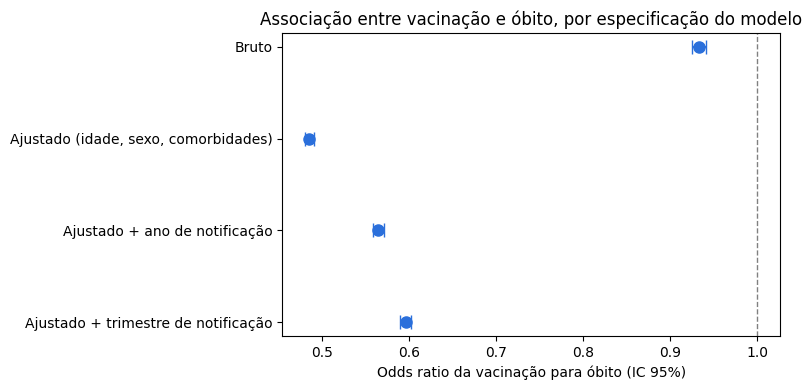

In [16]:
tabela4 = pd.DataFrame(resultados_modelos)
print("Tabela 4:")
print(tabela4.to_string(index=False))

ors = tabela4[tabela4["Medida"] == "OR"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(ors))[::-1]
erros = [ors["Estimativa"] - ors["IC 95% inf"], ors["IC 95% sup"] - ors["Estimativa"]]
ax.errorbar(ors["Estimativa"], y_pos, xerr=erros, fmt="o", color="#2a6fdb", capsize=5, markersize=8)
ax.axvline(1, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(ors["Modelo"])
ax.set_xlabel("Odds ratio da vacinação para óbito (IC 95%)")
ax.set_title("Associação entre vacinação e óbito, por especificação do modelo")
plt.tight_layout()
plt.show()


## 12. Modelo XGBoost

Mesmas cinco variáveis do modelo ajustado (sem o período).

In [17]:
FEATURES = ["VACINADO", "IDADE_ANOS", "SEXO_M", "N_COMORBIDADES", "COMORBIDADE_TODAS_FALTANTES"]
X = base[FEATURES]
y = base["OBITO"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

modelo_xgb = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="logloss", random_state=42,
)
modelo_xgb.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

## 13. Avaliação do modelo XGBoost

Casos no teste: 245,873
AUC: 0.708
Acuracia de referencia (classificar todos como sobreviventes): 69.5%

Matriz de confusao:
[[159283  11656]
 [ 60606  14328]]

Relatorio de classificacao:
              precision    recall  f1-score   support

           0      0.724     0.932     0.815    170939
           1      0.551     0.191     0.284     74934

    accuracy                          0.706    245873
   macro avg      0.638     0.562     0.550    245873
weighted avg      0.672     0.706     0.653    245873



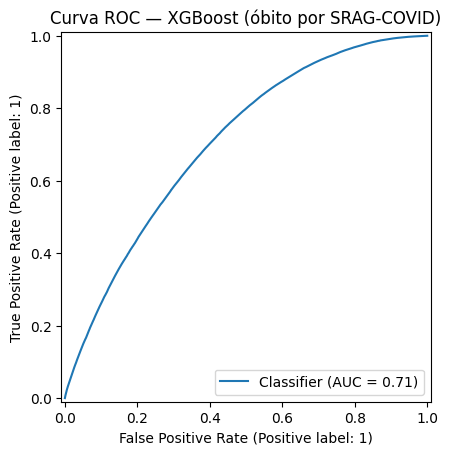

In [18]:
y_pred_proba = modelo_xgb.predict_proba(X_test)[:, 1]
y_pred = modelo_xgb.predict(X_test)

print(f"Casos no teste: {len(y_test):,}")
print(f"AUC: {roc_auc_score(y_test, y_pred_proba):.3f}")
print(f"Acuracia de referencia (classificar todos como sobreviventes): {(1 - y_test.mean())*100:.1f}%")
print()
print("Matriz de confusao:")
print(confusion_matrix(y_test, y_pred))
print()
print("Relatorio de classificacao:")
print(classification_report(y_test, y_pred, digits=3))

RocCurveDisplay.from_predictions(y_test, y_pred_proba)
plt.title("Curva ROC — XGBoost (óbito por SRAG-COVID)")
plt.show()


## 14. Importância de variáveis (SHAP)

O gráfico resumo e a média do SHAP usam o mesmo conjunto de teste completo.

Media do |SHAP| por variavel:
IDADE_ANOS                     0.633
VACINADO                       0.322
N_COMORBIDADES                 0.201
COMORBIDADE_TODAS_FALTANTES    0.089
SEXO_M                         0.084
dtype: float32


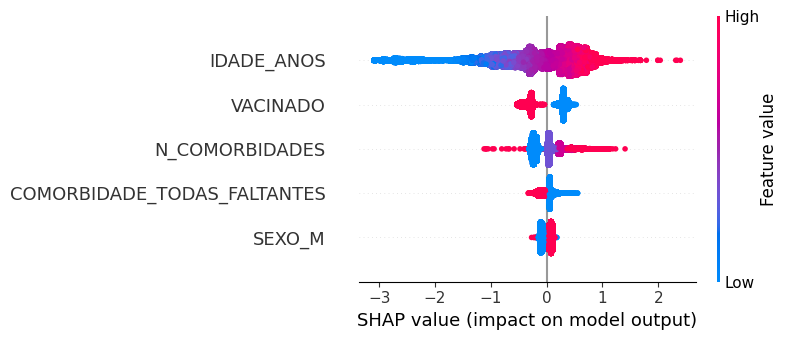

In [19]:
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer.shap_values(X_test)

importancia = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print("Media do |SHAP| por variavel:")
print(importancia.round(3))

shap.summary_plot(shap_values, X_test, show=True)


## 15. Análise de sensibilidade: incluindo `Ignorado` e `Não informado`

As categorias de status desconhecido entram como níveis adicionais, com `Nao`
como referência. Sem ajuste por período, para comparar com o modelo da seção 8.

In [20]:
sens = df[
    df["EVOLUCAO"].isin([1, 2])
    & df["CS_SEXO"].isin(["M", "F"])
    & df["IDADE_ANOS"].notna()
].copy()
sens["OBITO"] = (sens["EVOLUCAO"] == 2).astype(int)
sens["SEXO_M"] = (sens["CS_SEXO"] == "M").astype(int)

print(f"Casos: {len(sens):,}")
print(sens["VACINA_CAT"].value_counts())

modelo_sens = smf.logit(
    "OBITO ~ C(VACINA_CAT, Treatment(reference='Nao')) + " + COVARS,
    data=sens,
).fit()

or_sens = np.exp(modelo_sens.params)
ci_sens = np.exp(modelo_sens.conf_int())
ci_sens.columns = ["IC_2.5%", "IC_97.5%"]
print(pd.concat([or_sens.rename("Odds Ratio"), ci_sens], axis=1).round(3))

del modelo_sens, sens
gc.collect()


Casos: 1,507,332
VACINA_CAT
Sim              494860
Nao              488632
Nao_informado    318320
Ignorado         205520
Name: count, dtype: int64
Optimization terminated successfully.
         Current function value: 0.567515
         Iterations 6
                                                    Odds Ratio  IC_2.5%  IC_97.5%
Intercept                                                0.054    0.053     0.055
C(VACINA_CAT, Treatment(reference='Nao'))[T.Ign...       0.901    0.891     0.912
C(VACINA_CAT, Treatment(reference='Nao'))[T.Nao...       0.906    0.897     0.916
C(VACINA_CAT, Treatment(reference='Nao'))[T.Sim]         0.479    0.474     0.484
IDADE_ANOS                                               1.038    1.038     1.038
SEXO_M                                                   1.172    1.164     1.181
N_COMORBIDADES                                           1.224    1.217     1.230
COMORBIDADE_TODAS_FALTANTES                              0.845    0.836     0.854


5981

## 17. Validação cruzada e holdout temporal

1. **Validação cruzada (5 partições)** no XGBoost: a AUC é estável
2. **Holdout temporal**: modelo logístico ajustado treinado com 2021-2023 e
   avaliado em 2024-2025. O OR também é reestimado só com 2024-2025.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs = cross_val_score(modelo_xgb, X, y, cv=skf, scoring="roc_auc", n_jobs=1)
print("AUC por particao:", np.round(aucs, 3))
print(f"AUC media: {aucs.mean():.3f} (desvio-padrao {aucs.std():.3f})")


AUC por particao: [0.706 0.708 0.711 0.708 0.708]
AUC media: 0.708 (desvio-padrao 0.001)


In [23]:
treino = base[base["ano"].isin([2021, 2022, 2023])]
teste_temporal = base[base["ano"].isin([2024, 2025])]
print(f"Treino (2021-2023): {len(treino):,} casos")
print(f"Teste (2024-2025): {len(teste_temporal):,} casos")

m_treino = smf.logit(f"OBITO ~ VACINADO + {COVARS}", data=treino).fit(disp=0)
auc_holdout = roc_auc_score(teste_temporal["OBITO"], m_treino.predict(teste_temporal))
print(f"AUC no holdout temporal: {auc_holdout:.3f}")
print(extrair(m_treino, "OR treinado em 2021-2023", "OR"))

m_recente = smf.logit(f"OBITO ~ VACINADO + {COVARS}", data=teste_temporal).fit(disp=0)
print(extrair(m_recente, "OR reestimado em 2024-2025", "OR"))

del m_treino, m_recente, treino, teste_temporal
gc.collect()


Treino (2021-2023): 933,649 casos
Teste (2024-2025): 45,330 casos
AUC no holdout temporal: 0.693
{'Modelo': 'OR treinado em 2021-2023', 'Medida': 'OR', 'Estimativa': 0.494, 'IC 95% inf': 0.489, 'IC 95% sup': 0.499}
{'Modelo': 'OR reestimado em 2024-2025', 'Medida': 'OR', 'Estimativa': 0.911, 'IC 95% inf': 0.841, 'IC 95% sup': 0.987}


176

## 18. Tabela 5: OR ajustado da vacinação estimado por ano

Modelo ajustado (seção 8) estimado separadamente em cada ano de notificação.
O período não entra como covariável, por ser constante dentro de cada ano.

Tabela 5:
 Ano  Casos  Vacinados (%)  Estimativa  IC 95% inf  IC 95% sup
2021 661164           38.1       0.497       0.491       0.504
2022 224007           74.5       0.717       0.700       0.734
2023  48478           79.7       0.664       0.618       0.714
2024  28682           75.2       0.883       0.806       0.968
2025  16648           80.7       1.076       0.906       1.277
2026   4513           62.6       0.893       0.712       1.120


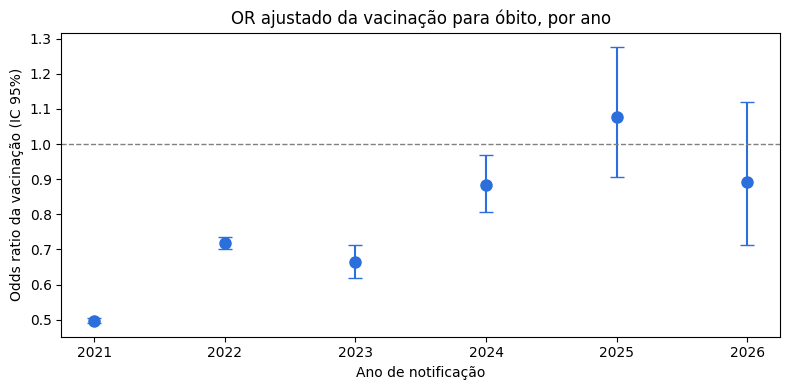

In [24]:
linhas = []
for a in sorted(base["ano"].unique()):
    s = base[base["ano"] == a]
    m = smf.logit(f"OBITO ~ VACINADO + {COVARS}", data=s).fit(disp=0)
    r = extrair(m, int(a), "OR")
    r["Casos"] = len(s)
    r["Vacinados (%)"] = round(s["VACINADO"].mean() * 100, 1)
    linhas.append(r)
    del m

tabela5 = pd.DataFrame(linhas).rename(columns={"Modelo": "Ano"})
tabela5 = tabela5[["Ano", "Casos", "Vacinados (%)", "Estimativa", "IC 95% inf", "IC 95% sup"]]
print("Tabela 5:")
print(tabela5.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
erros = [tabela5["Estimativa"] - tabela5["IC 95% inf"], tabela5["IC 95% sup"] - tabela5["Estimativa"]]
ax.errorbar(tabela5["Ano"], tabela5["Estimativa"], yerr=erros, fmt="o", color="#2a6fdb", capsize=5, markersize=8)
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(tabela5["Ano"])
ax.set_xlabel("Ano de notificação")
ax.set_ylabel("Odds ratio da vacinação (IC 95%)")
ax.set_title("OR ajustado da vacinação para óbito, por ano")
plt.tight_layout()
plt.show()


## 20. Regressão logística x XGBoost: matriz de confusão, F1 e limiar

Mesma partição de treino/teste da seção 12. Compara os dois modelos com o limiar padrão (0,5) e com o limiar igual à proporção de óbitos no treino. Gera a Tabela 4 do artigo.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

FEATURES = ["VACINADO", "IDADE_ANOS", "SEXO_M", "N_COMORBIDADES", "COMORBIDADE_TODAS_FALTANTES"]
X_train, X_test, y_train, y_test = train_test_split(
    base[FEATURES], base["OBITO"], test_size=0.25, random_state=42, stratify=base["OBITO"]
)
modelo_xgb = xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                               subsample=0.8, colsample_bytree=0.8,
                               eval_metric="logloss", random_state=42)
modelo_xgb.fit(X_train, y_train)
modelo_lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)

prob = {"Regressão logística": modelo_lr.predict_proba(X_test)[:, 1],
        "XGBoost": modelo_xgb.predict_proba(X_test)[:, 1]}
limiar_prev = y_train.mean()

def metricas(p, limiar):
    yp = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    return {"AUC": round(roc_auc_score(y_test, p), 3), "VP": tp, "FN": fn, "FP": fp, "VN": tn,
            "Acurácia (%)": round(accuracy_score(y_test, yp) * 100, 1),
            "Precisão (%)": round(precision_score(y_test, yp) * 100, 1),
            "Revocação (%)": round(recall_score(y_test, yp) * 100, 1),
            "Especificidade (%)": round(tn / (tn + fp) * 100, 1),
            "F1": round(f1_score(y_test, yp), 3)}

tabela4 = pd.DataFrame({f"{nome} (limiar {lim:.3f})": metricas(p, lim)
                        for lim in [0.5, limiar_prev] for nome, p in prob.items()})
print(f"Teste: {len(y_test):,} casos, {y_test.sum():,} óbitos")
tabela4

Teste: 245,873 casos, 74,934 óbitos


,Regressão logística (limiar 0.500),XGBoost (limiar 0.500),Regressão logística (limiar 0.305),XGBoost (limiar 0.305)
AUC,0.704,0.708,0.704,0.708
VP,15276.000,14328.000,51198.000,55239.000
FN,59658.000,60606.000,23736.000,19695.000
FP,13001.000,11656.000,66091.000,73982.000
VN,157938.000,159283.000,104848.000,96957.000
Acurácia (%),70.400,70.600,63.500,61.900
Precisão (%),54.000,55.100,43.700,42.700
Revocação (%),20.400,19.100,68.300,73.700
Especificidade (%),92.400,93.200,61.300,56.700
F1,0.296,0.284,0.533,0.541


## 21. Casos com status vacinal desconhecido

Perfil dos casos excluídos, distribuição por ano e cenários extremos (todos vacinados / todos não vacinados), com ajuste por trimestre.

In [26]:
sens = df[df["EVOLUCAO"].isin([1, 2]) & df["CS_SEXO"].isin(["M", "F"]) & df["IDADE_ANOS"].notna()].copy()
sens["OBITO"] = (sens["EVOLUCAO"] == 2).astype(int)
sens["SEXO_M"] = (sens["CS_SEXO"] == "M").astype(int)
sens["TRIMESTRE"] = sens["DT_NOTIFIC"].dt.to_period("Q").astype(str)
sens["GRUPO"] = np.where(sens["VACINA_CAT"].isin(["Sim", "Nao"]), sens["VACINA_CAT"], "Desconhecido")

g = sens.groupby("GRUPO")
print(pd.DataFrame({
    "Casos": g.size(),
    "Idade média": g["IDADE_ANOS"].mean().round(1),
    "≥1 comorbidade (%)": g["N_COMORBIDADES"].apply(lambda s: (s > 0).mean() * 100).round(1),
    "Óbito (%)": (g["OBITO"].mean() * 100).round(1),
}))
print("\n% de status desconhecido por ano:")
print((sens.groupby("ano")["GRUPO"].apply(lambda s: (s == "Desconhecido").mean() * 100)).round(1))

for nome, valor in [("todos vacinados", 1), ("todos não vacinados", 0)]:
    sens["VAC_CENARIO"] = np.select([sens["GRUPO"] == "Sim", sens["GRUPO"] == "Nao"], [1, 0], default=valor)
    m = smf.logit(f"OBITO ~ VAC_CENARIO + {COVARS} + C(TRIMESTRE)", data=sens).fit(disp=0)
    print(extrair(m, f"Cenário: desconhecidos = {nome}", "OR", var="VAC_CENARIO"))
    del m
gc.collect()

               Casos  Idade média  ≥1 comorbidade (%)  Óbito (%)
GRUPO                                                           
Desconhecido  523840         57.3                47.3       34.6
Nao           488632         49.7                41.8       31.2
Sim           494860         65.1                59.3       29.8

% de status desconhecido por ano:
ano
2021    43.9
2022     2.7
2023     1.1
2024     1.3
2025     0.9
2026     1.5
Name: GRUPO, dtype: float64
{'Modelo': 'Cenário: desconhecidos = todos vacinados', 'Medida': 'OR', 'Estimativa': 0.739, 'IC 95% inf': 0.733, 'IC 95% sup': 0.745}
{'Modelo': 'Cenário: desconhecidos = todos não vacinados', 'Medida': 'OR', 'Estimativa': 0.635, 'IC 95% inf': 0.628, 'IC 95% sup': 0.641}


2934

## 22. Composição dos grupos por ano

Idade média e proporção de óbitos de vacinados e não vacinados em cada ano.

In [27]:
print(base.pivot_table(index="ano", columns="VACINADO", values="IDADE_ANOS", aggfunc="mean").round(1))
print(base.pivot_table(index="ano", columns="VACINADO", values="OBITO", aggfunc="mean").mul(100).round(1))

# AUC da regressão logística nos próprios dados de treino da validação temporal (2021-2023)
treino = base[base["ano"].isin([2021, 2022, 2023])]
m_treino = smf.logit(f"OBITO ~ VACINADO + {COVARS}", data=treino).fit(disp=0)
print(f"AUC no treino 2021-2023: {roc_auc_score(treino['OBITO'], m_treino.predict(treino)):.3f}")
del m_treino, treino
gc.collect()

VACINADO     0     1
ano                 
2021      51.5  63.4
2022      47.3  67.7
2023      24.1  67.0
2024      24.1  66.4
2025      12.5  58.5
2026      18.3  65.1
VACINADO     0     1
ano                 
2021      32.9  31.9
2022      26.4  29.9
2023      14.1  23.7
2024      11.4  21.9
2025       6.1  19.2
2026       8.8  20.8
AUC no treino 2021-2023: 0.705


0